In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [71]:
# Carreguem la base de dades
df = pd.read_csv('cumulative.csv')

# Seleccionem només les variables d'interés
vars_interés = ["kepoi_name", "koi_disposition", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec", "koi_period", "koi_impact", "koi_duration", "koi_depth", "koi_prad", "koi_teq", "koi_insol", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]
df = df[vars_interés]
df.head()

,kepoi_name,koi_disposition,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_steff,koi_slogg,koi_srad,koi_kepmag
0,K00752.01,CONFIRMED,0,0,0,0,9.488036,0.146,2.95750,615.8,2.26,793.0,93.59,5455.0,4.467,0.927,15.347
1,K00752.02,CONFIRMED,0,0,0,0,54.418383,0.586,4.50700,874.8,2.83,443.0,9.11,5455.0,4.467,0.927,15.347
2,K00753.01,FALSE POSITIVE,0,1,0,0,19.899140,0.969,1.78220,10829.0,14.60,638.0,39.30,5853.0,4.544,0.868,15.436
3,K00754.01,FALSE POSITIVE,0,1,0,0,1.736952,1.276,2.40641,8079.2,33.46,1395.0,891.96,5805.0,4.564,0.791,15.597
4,K00755.01,CONFIRMED,0,0,0,0,2.525592,0.701,1.65450,603.3,2.75,1406.0,926.16,6031.0,4.438,1.046,15.509


In [72]:
# Observem el nombre d'oservacions faltants per variable
print(df.isnull().sum())

kepoi_name           0
koi_disposition      0
koi_fpflag_nt        0
koi_fpflag_ss        0
koi_fpflag_co        0
koi_fpflag_ec        0
koi_period           0
koi_impact         363
koi_duration         0
koi_depth          363
koi_prad           363
koi_teq            363
koi_insol          321
koi_steff          363
koi_slogg          363
koi_srad           363
koi_kepmag           1
dtype: int64


In [15]:
# Eliminem les observacions amb valors faltants
df = df.dropna()
len(df)

9200

In [16]:
# Fem un resum de les variables (les 4 primeres son binàries)
desc_stats = df.describe().transpose()
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max
koi_fpflag_nt,9200.0,0.170761,0.376320,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_fpflag_ss,9200.0,0.238043,0.425909,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_fpflag_co,9200.0,0.200870,0.400672,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_fpflag_ec,9200.0,0.123913,0.329500,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_period,9200.0,74.315762,1360.612589,0.241843,2.683239,9.300443,36.873842,1.299958e+05
koi_impact,9200.0,0.735059,3.349011,0.000000,0.197000,0.537000,0.888250,1.008060e+02
koi_duration,9200.0,5.654852,6.500038,0.052000,2.453450,3.823930,6.291207,1.385400e+02
koi_depth,9200.0,23789.863435,82247.031935,0.000000,159.900000,421.000000,1473.100000,1.541400e+06
koi_prad,9200.0,102.897725,3077.806350,0.080000,1.400000,2.390000,14.930000,2.003460e+05
koi_teq,9200.0,1085.356848,856.393194,25.000000,539.000000,878.000000,1379.000000,1.466700e+04


/tmp/ipykernel_513530/2890269325.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='koi_disposition', data=df, palette='viridis')


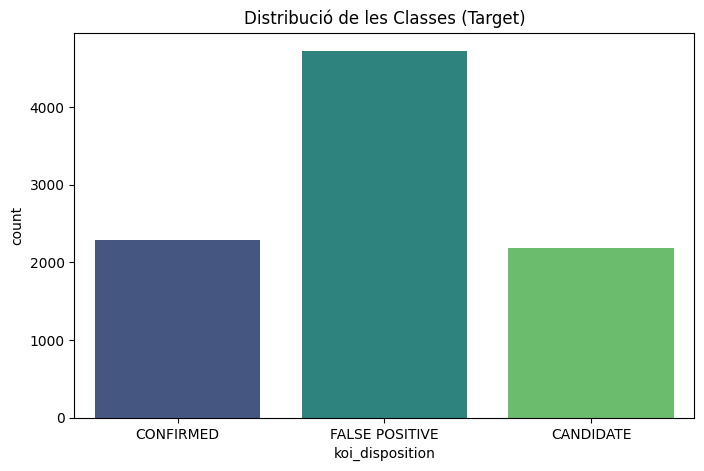

In [ ]:
# Visualització de la Variable Objectiu (Target)
plt.figure(figsize=(8, 5))
sns.countplot(x='koi_disposition', data=df, palette='viridis')
plt.title('Distribució de les Classes (Target)')
plt.show()

In [ ]:
# Ja que només volem predir si les observacions son falsos positius o confirmats, eliminem les que tenen etiqueta 'CANDIDATE'
df = df[df["koi_disposition"] != "CANDIDATE"]
desc_stats = df.describe().transpose()
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max
koi_fpflag_nt,7015.0,0.223949,0.416918,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_fpflag_ss,7015.0,0.307627,0.461544,0.000000,0.000000,0.000000,1.000000,1.000000e+00
koi_fpflag_co,7015.0,0.263435,0.440528,0.000000,0.000000,0.000000,1.000000,1.000000e+00
koi_fpflag_ec,7015.0,0.162509,0.368943,0.000000,0.000000,0.000000,0.000000,1.000000e+00
koi_period,7015.0,56.571983,119.912971,0.241843,2.199067,8.214299,31.856147,1.071233e+03
koi_impact,7015.0,0.796721,3.668884,0.000000,0.224000,0.576000,0.916000,1.008060e+02
koi_duration,7015.0,5.916695,7.002675,0.104600,2.559650,3.950000,6.472000,1.385400e+02
koi_depth,7015.0,30619.156336,92880.570679,0.800000,184.500000,507.300000,2768.400000,1.541400e+06
koi_prad,7015.0,129.985577,3519.874708,0.080000,1.520000,2.680000,25.435000,2.003460e+05
koi_teq,7015.0,1148.566643,898.387364,92.000000,559.000000,928.000000,1496.500000,1.466700e+04


/tmp/ipykernel_513530/2451340338.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette='Reds')
/tmp/ipykernel_513530/2451340338.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette='Reds')
/tmp/ipykernel_513530/2451340338.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, ax=axes[i], palette='Reds')
/tmp/ipykernel_513530/2451340338.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the

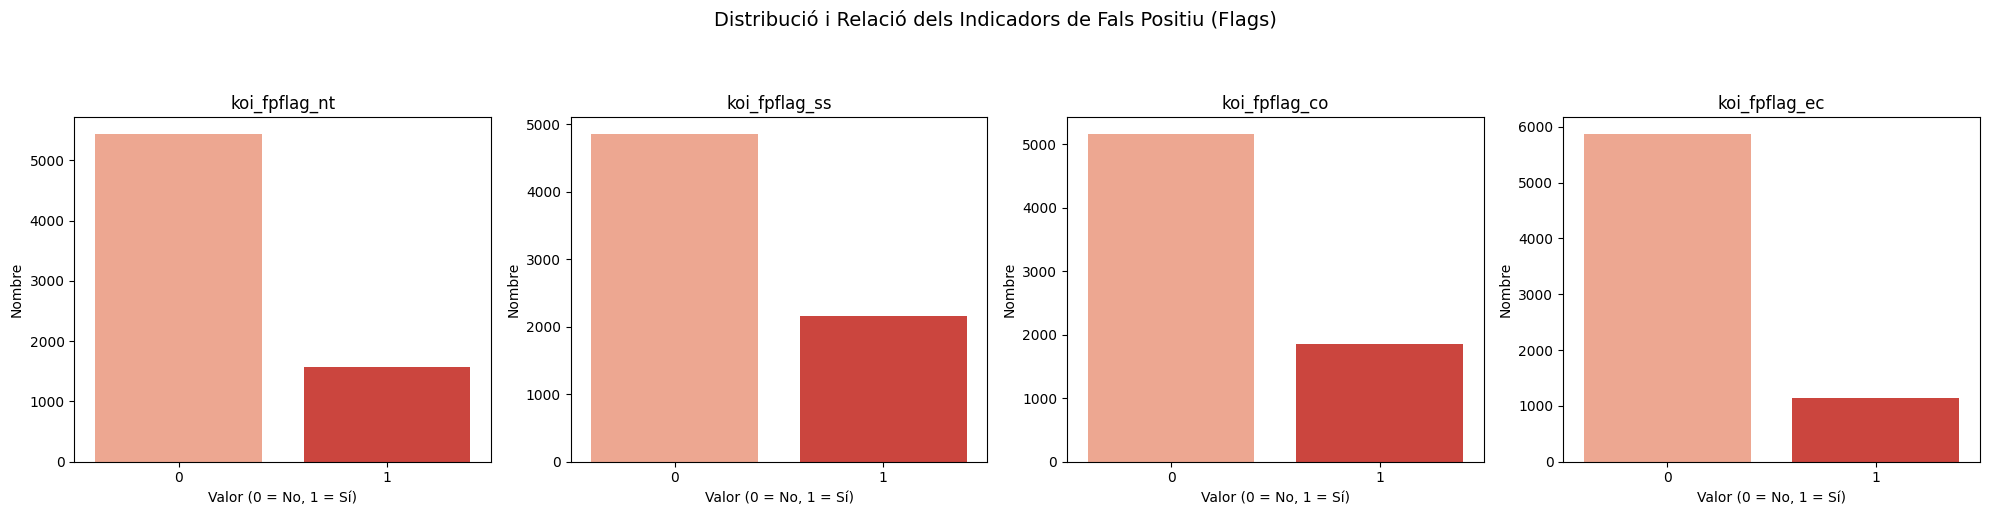

In [56]:
# Anàlisi de les Variables Binàries (Flags de Fals Positiu)
flag_vars = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Distribució i Relació dels Indicadors de Fals Positiu (Flags)', fontsize=14, y=1.02)

for i, col in enumerate(flag_vars):
    # Gràfic de comptatge de 0s i 1s
    sns.countplot(x=col, data=df, ax=axes[i], palette='Reds')
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('Valor (0 = No, 1 = Sí)')
    axes[i].set_ylabel('Nombre')

plt.tight_layout(rect=[0, 0, 1, 0.95]) # Ajustar per deixar espai al títol
plt.show()

In [26]:
# Observem la relació entre el primer indicador de fals positiu i la variable objectiu
print("\nMatriu de Freqüència: koi_disposition vs koi_fpflag_nt")
print(pd.crosstab(df['koi_disposition'], df['koi_fpflag_nt']))


Matriu de Freqüència: koi_disposition vs koi_fpflag_nt
koi_fpflag_nt       0     1
koi_disposition            
CONFIRMED        2271    21
FALSE POSITIVE   3173  1550


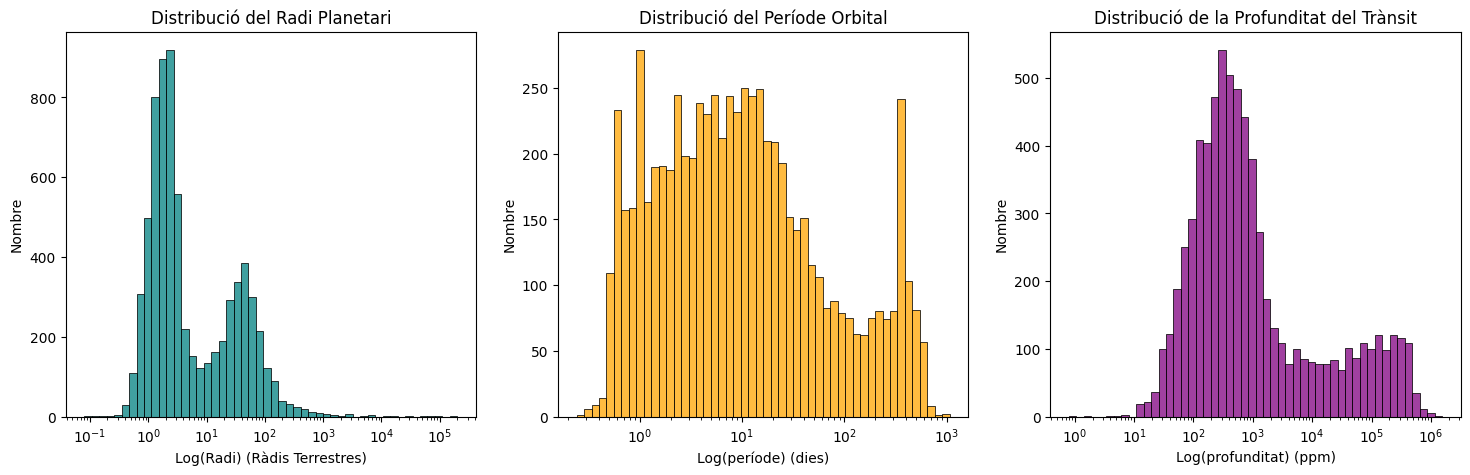

In [54]:
# Histogrames de variables clau (amb escala logarítmica per veure millor els atípics)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Radi del planeta
sns.histplot(df['koi_prad'].dropna(), bins=50, ax=axes[0], log_scale=True, color='teal')
axes[0].set_title('Distribució del Radi Planetari')
axes[0].set_xlabel('Log(Radi) (Ràdis Terrestres)')
axes[0].set_ylabel('Nombre')

# Període orbital
sns.histplot(df['koi_period'].dropna(), bins=50, ax=axes[1], log_scale=True, color='orange')
axes[1].set_title('Distribució del Període Orbital')
axes[1].set_xlabel('Log(període) (dies)')
axes[1].set_ylabel('Nombre')

# Profunditat del trànsit
sns.histplot(df['koi_depth'].dropna(), bins=50, ax=axes[2], log_scale=True, color='purple')
axes[2].set_title('Distribució de la Profunditat del Trànsit')
axes[2].set_xlabel('Log(profunditat) (ppm)')
axes[2].set_ylabel('Nombre')
plt.show()

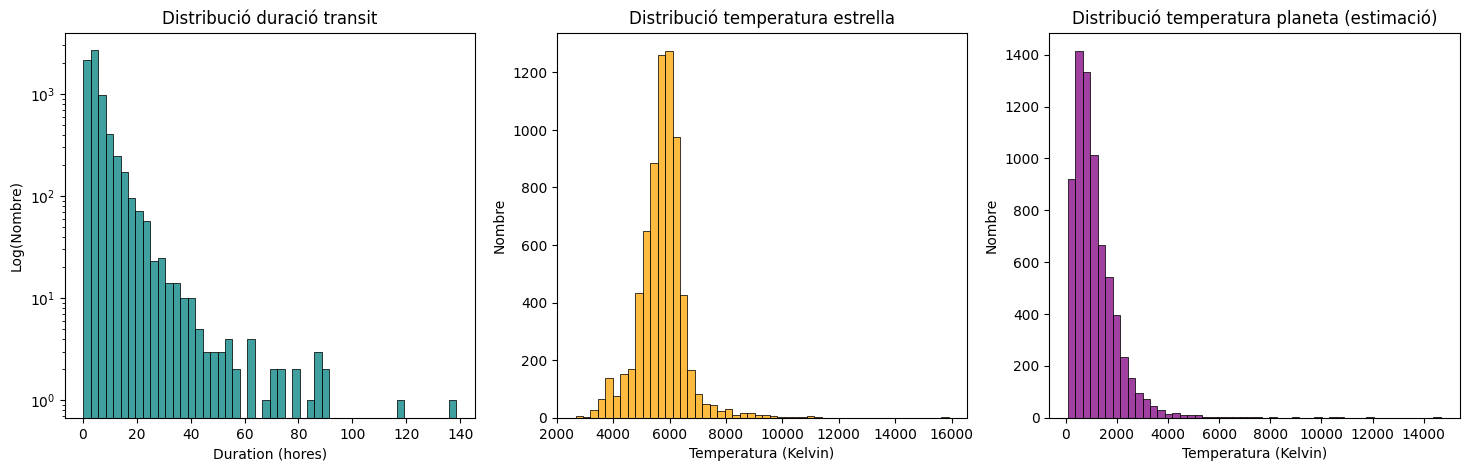

In [55]:
# Més Histogrames de variables predictores
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Duració del trànsit
sns.histplot(df['koi_duration'].dropna(), bins=50, ax=axes[0], color='teal')
axes[0].set_title('Distribució duració transit')
axes[0].set_xlabel('Duration (hores)')
axes[0].set_yscale('log')
axes[0].set_ylabel('Log(Nombre)')

# Temperatura de la estrella
sns.histplot(df['koi_steff'].dropna(), bins=50, ax=axes[1], color='orange')
axes[1].set_title('Distribució temperatura estrella')
axes[1].set_xlabel('Temperatura (Kelvin)')
axes[1].set_ylabel('Nombre')

# Estimació temperatura del planeta
sns.histplot(df['koi_teq'].dropna(), bins=50, ax=axes[2], color='purple')
axes[2].set_title('Distribució temperatura planeta (estimació)')
axes[2].set_xlabel('Temperatura (Kelvin)')
axes[2].set_ylabel('Nombre')
plt.show()

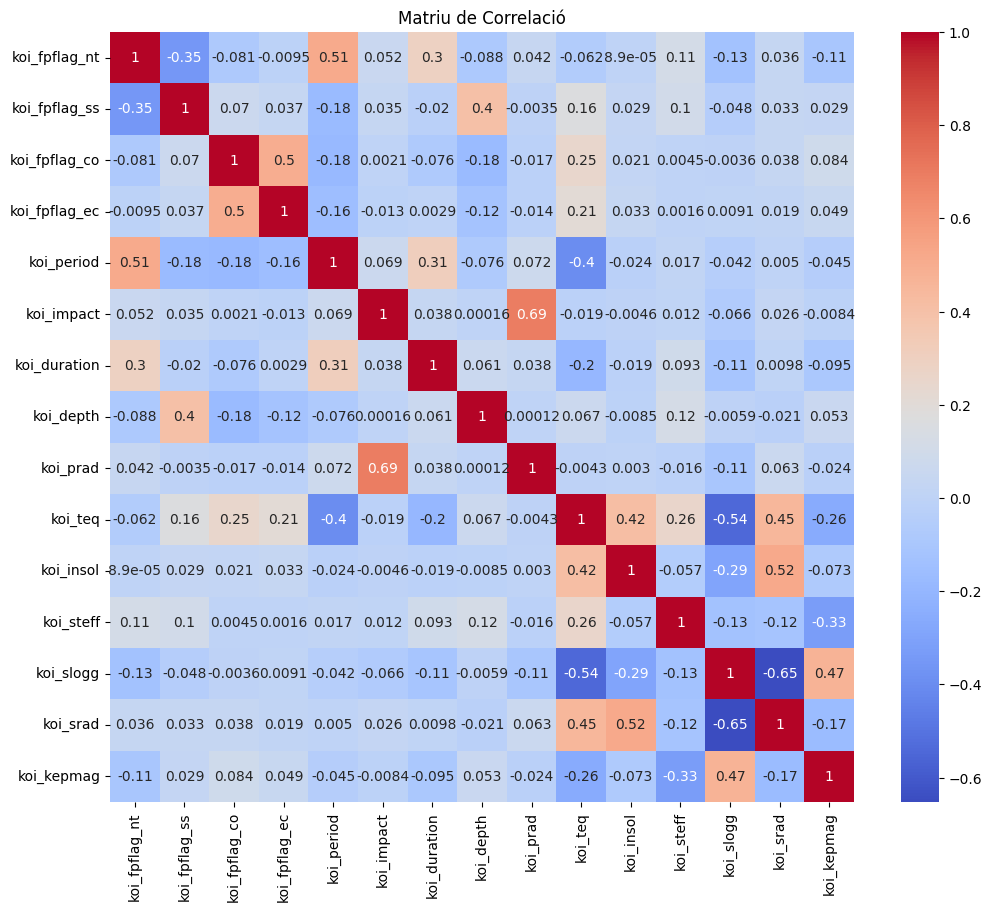

In [ ]:
# Correlacions
plt.figure(figsize=(12, 10))
# Seleccionem només numèriques per la matriu
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), cmap='coolwarm', annot=True)
plt.title('Matriu de Correlació')
plt.show()

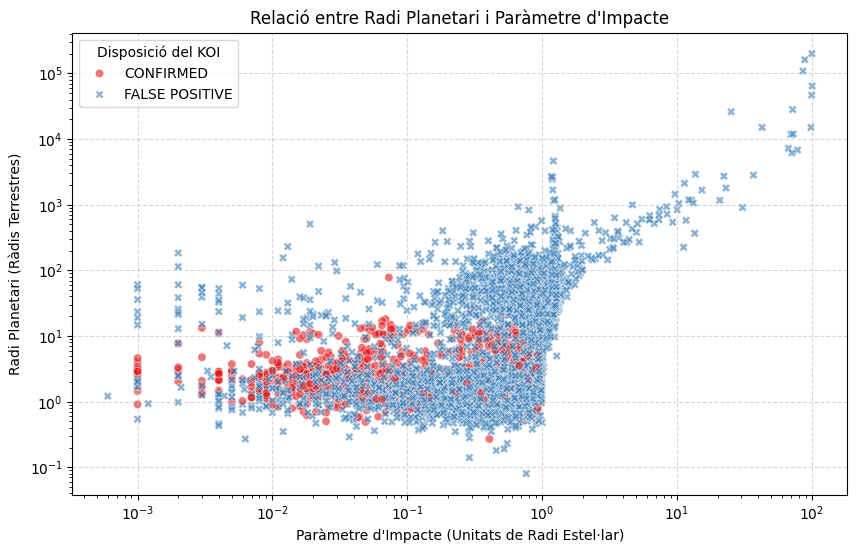

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Creació del diagrama de dispersió (Scatter Plot)
sns.scatterplot(
    data=df,
    x='koi_impact',
    y='koi_prad',
    hue='koi_disposition', 
    style='koi_disposition',
    palette='Set1',
    alpha=0.6 
)

plt.title('Relació entre Radi Planetari i Paràmetre d\'Impacte')
plt.xlabel('Paràmetre d\'Impacte (Unitats de Radi Estel·lar)')
plt.ylabel('Radi Planetari (Ràdis Terrestres)')

# Apliquem escala logarítmica a koi_prad per gestionar valors atípics
plt.xscale('log')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title='Disposició del KOI')
plt.show()

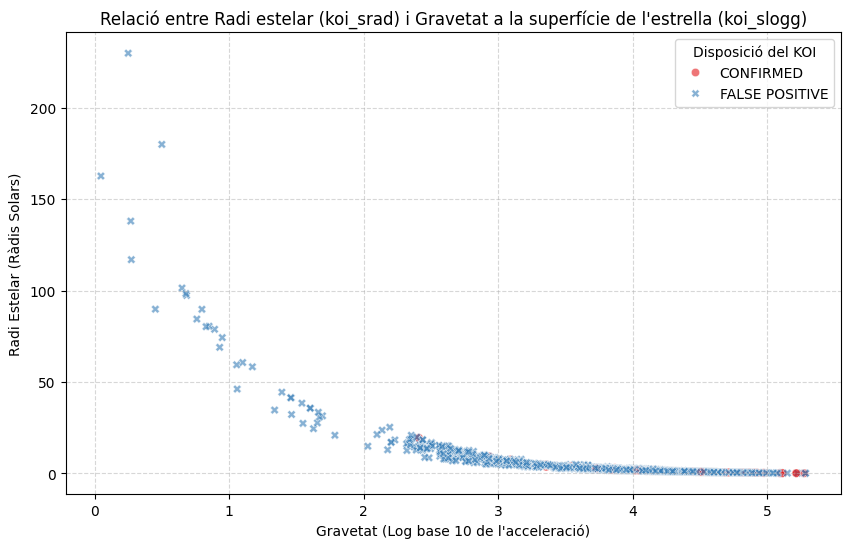

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Creació del diagrama de dispersió (Scatter Plot)
sns.scatterplot(
    data=df,
    x='koi_slogg',
    y='koi_srad',
    hue='koi_disposition', 
    style='koi_disposition',
    palette='Set1',
    alpha=0.6
)

plt.title('Relació entre Radi estelar (koi_srad) i Gravetat a la superfície de l\'estrella (koi_slogg)')
plt.xlabel('Gravetat (Log base 10 de l\'acceleració)')
plt.ylabel('Radi Estelar (Ràdis Solars)')

plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title='Disposició del KOI')
plt.show()